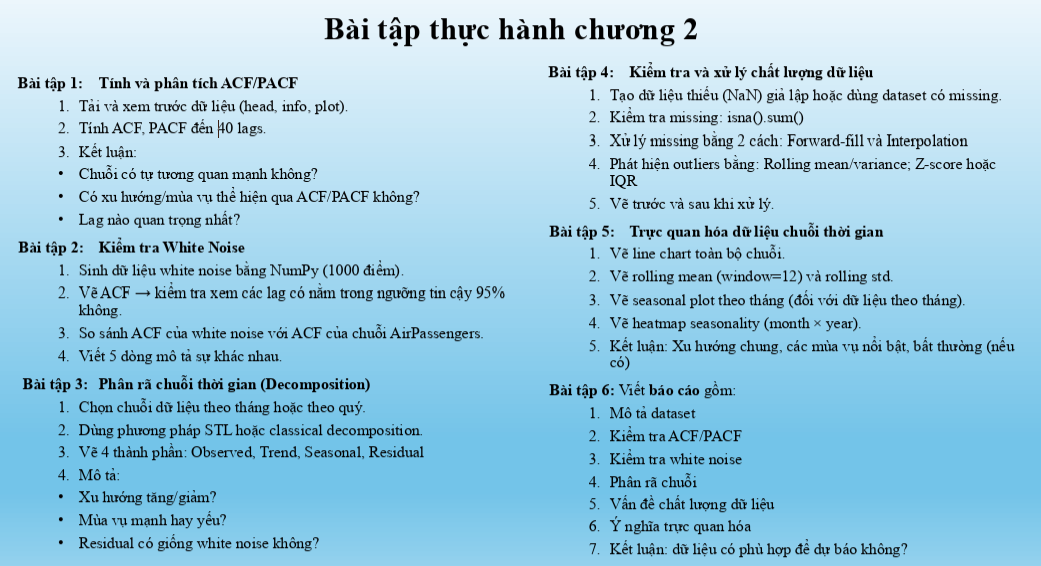

# Import libraries

In [23]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

# Load dataset

In [24]:
df_raw = pd.read_csv(r'T:\coding\time-series-practice\lab1\AirPassengers.csv')
print(df_raw.shape)
display(df_raw.head())
display(df_raw.tail())
df_raw.info()

(144, 3)


,rownames,time,value
0,1,1949.000000,112
1,2,1949.083333,118
2,3,1949.166667,132
3,4,1949.250000,129
4,5,1949.333333,121


,rownames,time,value
139,140,1960.583333,606
140,141,1960.666667,508
141,142,1960.750000,461
142,143,1960.833333,390
143,144,1960.916667,432


<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  144 non-null    int64  
 1   time      144 non-null    float64
 2   value     144 non-null    int64  
dtypes: float64(1), int64(2)
memory usage: 3.5 KB


| Column   | Meaning                                  | Unit      | Role      |
|----------|------------------------------------------|-----------|-----------|
| rownames | Row index from R export                  | -         | Drop      |
| time     | Fractional year                          | Year      | Timestamp |
| value    | Total intl airline passengers/month      | Thousands | Target    |

In [25]:
display(df_raw.describe())
print("nulls:", df_raw.isnull().sum().to_dict())
print("duplicate time values:", df_raw['time'].duplicated().sum())

,rownames,time,value
count,144.000000,144.000000,144.000000
mean,72.500000,1954.958333,280.298611
std,41.713307,3.476109,119.966317
min,1.000000,1949.000000,104.000000
25%,36.750000,1951.979167,180.000000
50%,72.500000,1954.958333,265.500000
75%,108.250000,1957.937500,360.500000
max,144.000000,1960.916667,622.000000


nulls: {'rownames': 0, 'time': 0, 'value': 0}
duplicate time values: 0


Cột `time` đang là năm dạng số thập phân (1949.083 = tháng 2/1949), nên đổi sang ngày tháng thật. Bỏ `rownames`, rồi dùng assert để chắc là chuỗi đủ từ 1949-01 đến 1960-12, không trùng, không thiếu tháng nào.

In [26]:
df = df_raw.copy()

# Parse fractional year -> proper datetime
df['Year']  = np.floor(df['time']).astype(int)
df['Month'] = np.round((df['time'] - df['Year']) * 12 + 1).astype(int)
df['Date']  = pd.to_datetime(df[['Year', 'Month']].assign(DAY=1))
df = df[['Date', 'value']].rename(columns={'value': 'Passengers'})

# Verify
assert df['Date'].min() == pd.Timestamp('1949-01-01'), "Start date wrong"
assert df['Date'].max() == pd.Timestamp('1960-12-01'), "End date wrong"
assert df['Date'].duplicated().sum() == 0, "Duplicate dates found"
assert df['Date'].is_monotonic_increasing, "Dates not sorted"

full_range = pd.date_range('1949-01-01', '1960-12-01', freq='MS')
assert len(full_range.difference(df['Date'])) == 0, "Gap in time series"

print("All checks passed.")
display(df.head(3))

All checks passed.


,Date,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132


| Column     | Role      | Notes                                      |
|------------|-----------|--------------------------------------------|
| Date       | Timestamp | Set as index before modeling               |
| Passengers | Target    | Log-transform likely needed (multiplicative)|
| rownames   | Dropped   | R artifact, no business value              |
| time       | Dropped   | Replaced by Date                           |

In [27]:
# Basic quality checks
print(f"value range: [{df['Passengers'].min()}, {df['Passengers'].max()}]")
print("any <= 0:", (df['Passengers'] <= 0).any())

value range: [104, 622]
any <= 0: False


## Tách train / test

Mọi bước EDA và mọi quyết định mô hình hoá (biến đổi log, bậc sai phân d và D, phát hiện outlier) chỉ dùng **train**. 12 tháng cuối (1960) được giữ làm hold-out để tránh rò rỉ thông tin khi đánh giá dự báo về sau.

Gán tần suất `MS` cho chuỗi, rồi cắt 12 tháng cuối làm test. Từ đây trở xuống chỉ dùng `train`.

In [28]:
h = 12  # horizon dự báo = 12 tháng cuối (1960) giữ làm hold-out

full = df.set_index('Date')['Passengers'].asfreq('MS')
train, test = full.iloc[:-h], full.iloc[-h:]

assert len(train) % 12 == 0
print("train:", train.index[0].strftime('%Y-%m'), "->", train.index[-1].strftime('%Y-%m'), len(train))
print("test :", test.index[0].strftime('%Y-%m'), "->", test.index[-1].strftime('%Y-%m'), len(test))

train: 1949-01 -> 1959-12 132
test : 1960-01 -> 1960-12 12


## 1. Quan sát chuỗi

Vì bảng thống kê mô tả tổng hợp không giữ được tính thứ tự của thời gian và làm mất hoàn toàn cấu trúc thời gian của dữ liệu, cần visualize chuỗi thời gian bằng line plot:

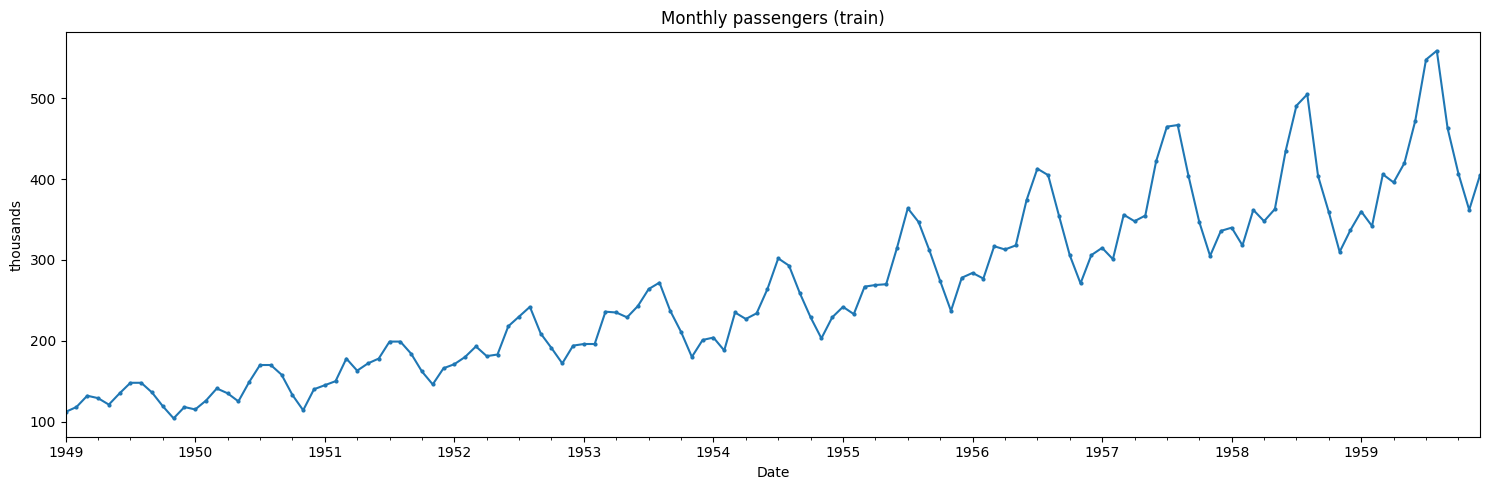

In [29]:
fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, marker="o", markersize=2)
ax.set(title='Monthly passengers (train)', ylabel='thousands')
plt.tight_layout()
plt.show()

## 2. Trend and Variability analysis

Line Plot đã giúp nhận diện sơ bộ sự tồn tại của xu hướng biến động của chuỗi theo thời gian. Và line plot còn bao gồm các dao động ngắn hạn và yếu tố mùa vụ nên có thể làm  che khuất đặc điểm của xu hướng dài hạn. Vì vậy, cần tiến hành trend analysis nhằm làm rõ hướng, hình dạng và sự thay đổi của xu hướng theo thời gian. 

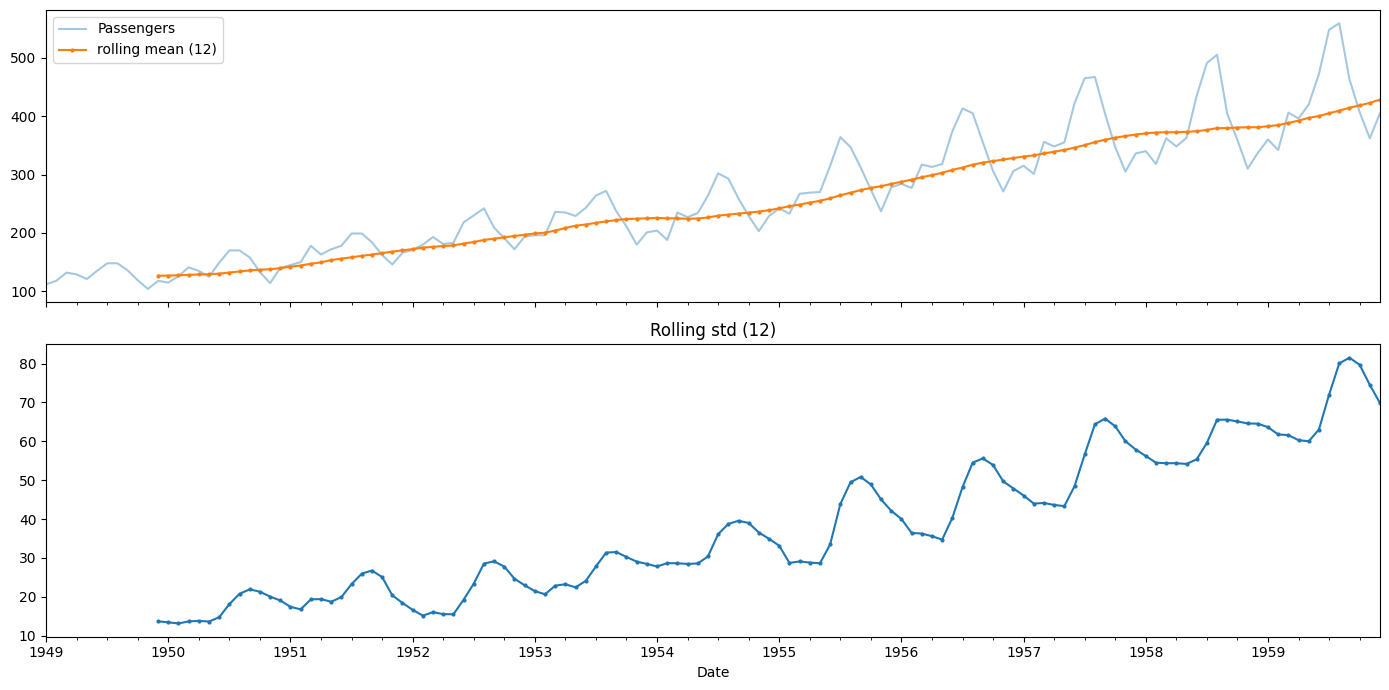

In [30]:
roll_mean = train.rolling(12).mean()
roll_std = train.rolling(12).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
train.plot(ax=ax1, alpha=0.4, label='Passengers')
roll_mean.plot(ax=ax1, label='rolling mean (12)', marker="o", markersize=2)
ax1.legend()
roll_std.plot(ax=ax2, title='Rolling std (12)', marker="o", markersize=2)
plt.tight_layout()
plt.show()

## 3. Seasonality analysis

Seasonal plot vẽ mỗi năm thành một đường theo tháng. 

Trục x là tháng trong năm (1-12), trục y là số hành khách. Mỗi đường là một năm, màu từ tím (1949) đến vàng (1959). 

Nếu mùa vụ ổn định thì các đường có cùng hình dạng.

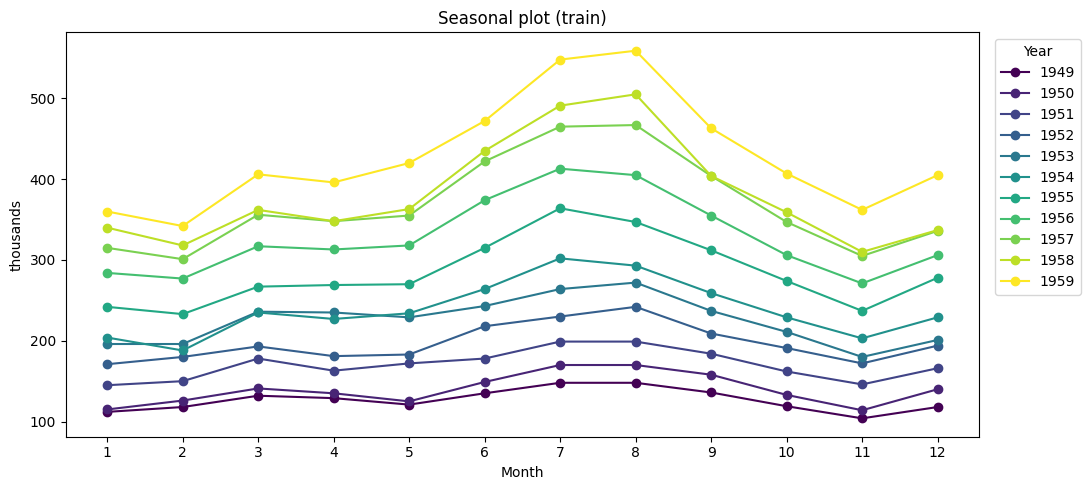

In [31]:
tdf = train.to_frame('Passengers')
tdf['Year'] = tdf.index.year
tdf['Month'] = tdf.index.month

pivot = tdf.pivot(index='Month', columns='Year', values='Passengers')

fig, ax = plt.subplots(figsize=(11, 5))
pivot.plot(ax=ax, marker='o', colormap='viridis')
ax.set(title='Seasonal plot (train)', xlabel='Month', ylabel='thousands')
ax.set_xticks(range(1, 13))
ax.legend(title='Year', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

Heatmap số hành khách theo tháng (hàng) và năm (cột).

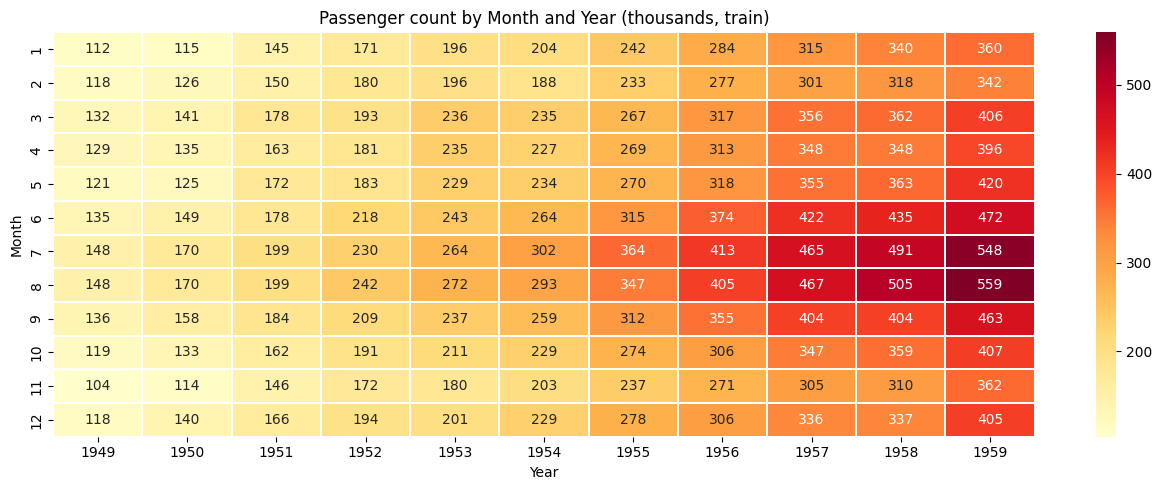

In [32]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pivot, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=0.3, ax=ax)
ax.set_title('Passenger count by Month and Year (thousands, train)')
plt.tight_layout()
plt.show()

## 4. Log transformation

raw: std min = 13.720, std max = 69.830, std max/min = 5.09
log: std min = 0.108, std max = 0.160, std max/min = 1.48


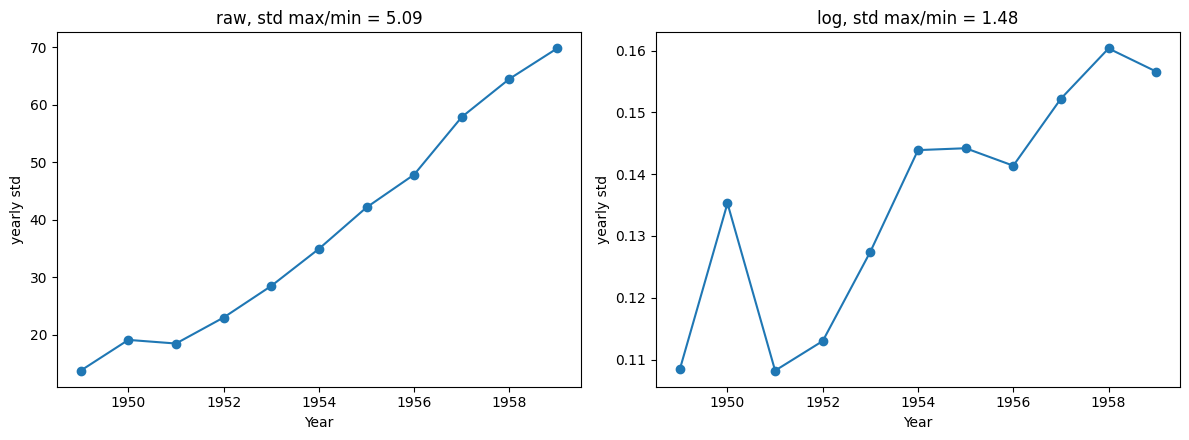

In [33]:
# So sánh độ biến động theo năm: nếu std tăng theo mức (mùa vụ nhân) thì max/min lớn,
# sau log mà max/min gần 1 thì phương sai đã ổn định
log_train = np.log(train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, (name, s) in zip(axes, [('raw', train), ('log', log_train)]):
    yr_std = s.groupby(s.index.year).std()
    ratio = yr_std.max() / yr_std.min()
    print(f"{name}: std min = {yr_std.min():.3f}, std max = {yr_std.max():.3f}, std max/min = {ratio:.2f}")
    ax.plot(yr_std.index, yr_std.values, marker='o')
    ax.set(xlabel='Year', ylabel='yearly std', title=f'{name}, std max/min = {ratio:.2f}')
plt.tight_layout()
plt.show()

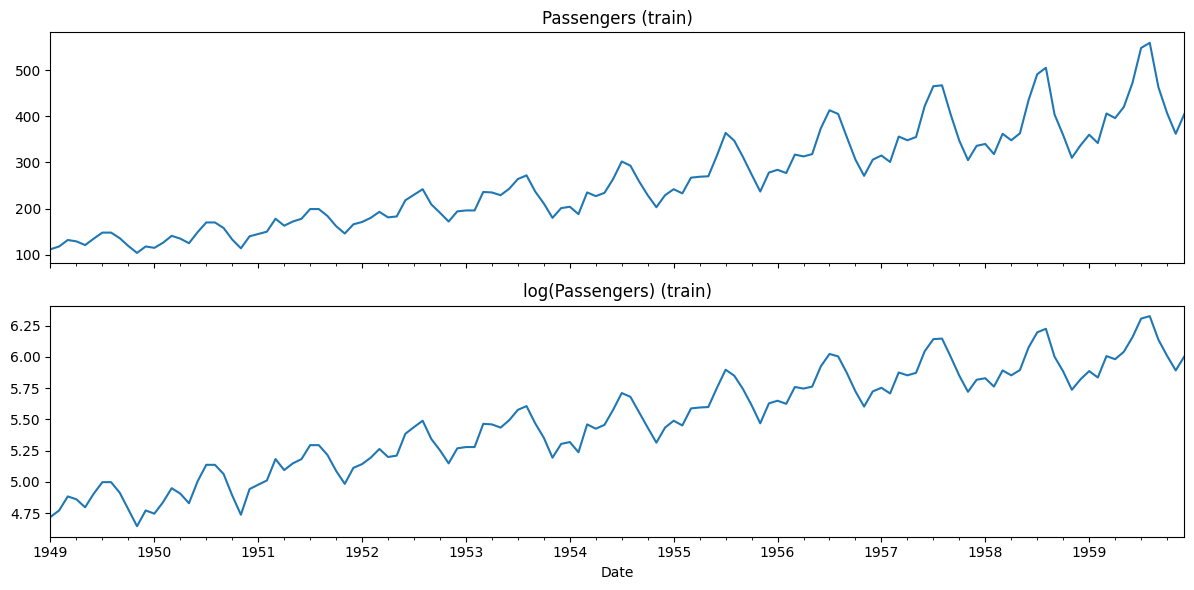

In [34]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
train.plot(ax=ax1, title='Passengers (train)')
log_train.plot(ax=ax2, title='log(Passengers) (train)')
plt.tight_layout()
plt.show()


## 5. Phân rã STL (thang log)

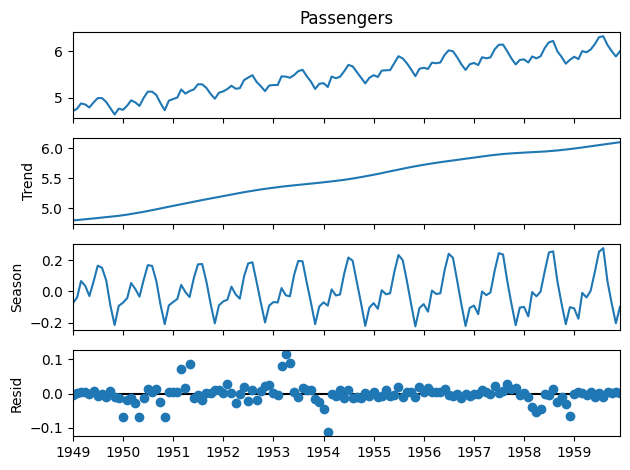

In [35]:
stl_res = STL(log_train, period=12, robust=True).fit()
R = stl_res.resid
stl_res.plot()
plt.tight_layout()
plt.show()

# Residual analysis

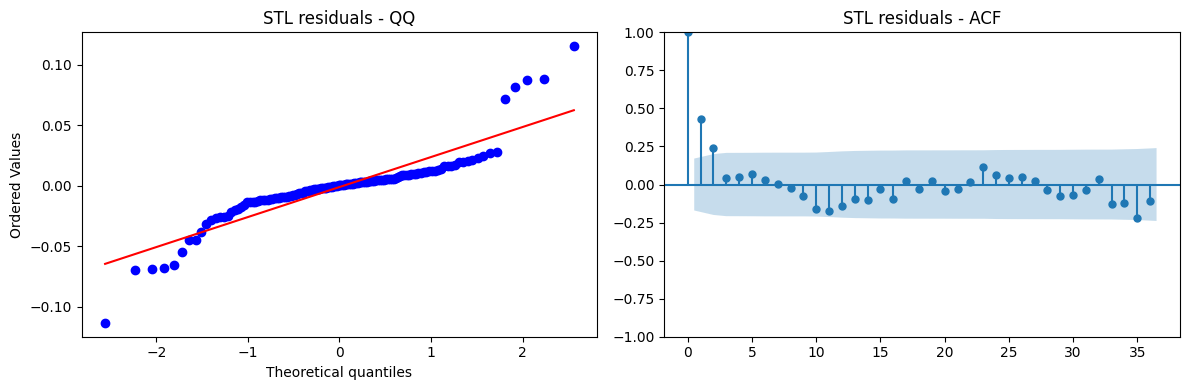

      lb_stat  lb_pvalue
12  46.313903   0.000006
24  54.183044   0.000403


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(R, plot=axes[0])
axes[0].set_title('STL residuals - QQ')
plot_acf(R, lags=36, ax=axes[1])
axes[1].set_title('STL residuals - ACF')
plt.tight_layout()
plt.show()

print(acorr_ljungbox(R, lags=[12, 24], return_df=True))

## 6. ACF, PACF

ACF và PACF của chuỗi train gốc, 40 lags.

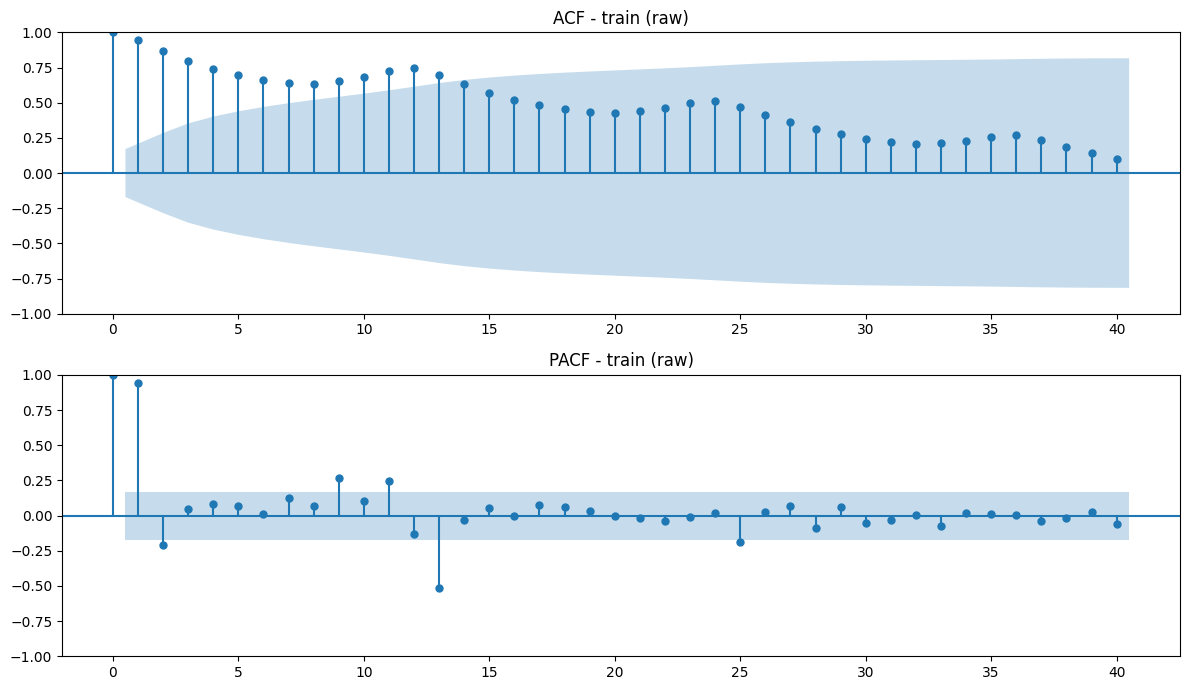

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(train, lags=40, ax=axes[0])
plot_pacf(train, lags=40, method='ywm', ax=axes[1])
axes[0].set_title('ACF - train (raw)')
axes[1].set_title('PACF - train (raw)')
plt.tight_layout()
plt.show()

#  BT2. White noise và so sánh với AirPassengers

Sinh 1000 điểm white noise từ phân phối chuẩn bằng NumPy (seed cố định), rồi vẽ ACF 40 lags với dải tin cậy 95% để kiểm tra các lag có nằm trong dải hay không.

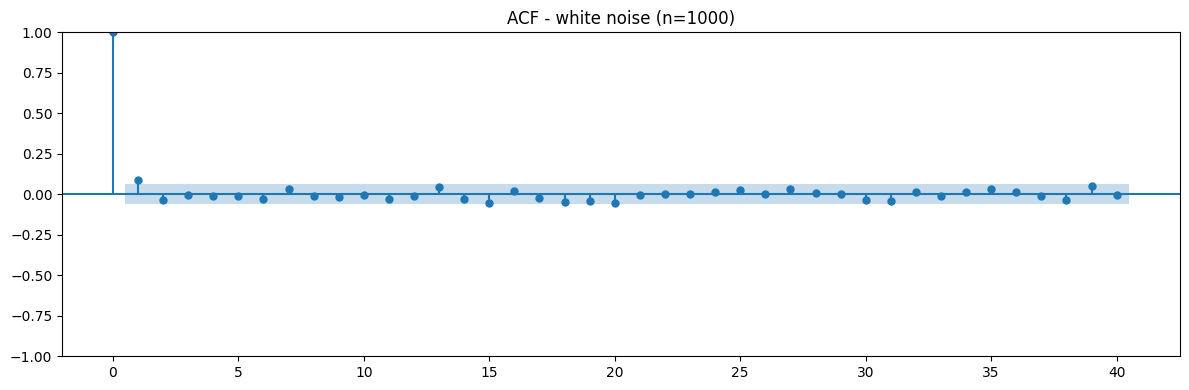

In [38]:
rng_wn = np.random.default_rng(42)
wn = pd.Series(rng_wn.normal(size=1000))

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(wn, lags=40, bartlett_confint=False, ax=ax)
ax.set_title('ACF - white noise (n=1000)')
plt.tight_layout()
plt.show()

**ACF của white noise 1000 điểm.** Các thanh sát 0, dải 95% chỉ khoảng ±0.062 vì n = 1000. Chỉ lag 1 (0.087) nhô nhẹ ra ngoài dải. Điều này bình thường: với dải 95%, chuỗi thuần nhiễu vẫn có khoảng 5% lag (tức 2/40) vượt dải do ngẫu nhiên. Vậy các lag nằm trong ngưỡng tin cậy 95%, nhất quán với white noise.

So sánh ACF của white noise với ACF của AirPassengers: đếm số lag nằm ngoài dải 95% (trong 40 lag) và lag 1 của hai chuỗi.

In [39]:
for name, s in [('white noise', wn), ('AirPassengers (train)', train)]:
    band = 1.96 / np.sqrt(len(s))
    r = acf(s, nlags=40)[1:]
    print(f"{name}: lag ngoài dải 95% = {(np.abs(r) > band).sum()}/40, ACF lag 1 = {r[0]:.3f}")

white noise: lag ngoài dải 95% = 1/40, ACF lag 1 = 0.087
AirPassengers (train): lag ngoài dải 95% = 38/40, ACF lag 1 = 0.942


Vẽ ACF của hai chuỗi cạnh nhau, cùng thang trục y.

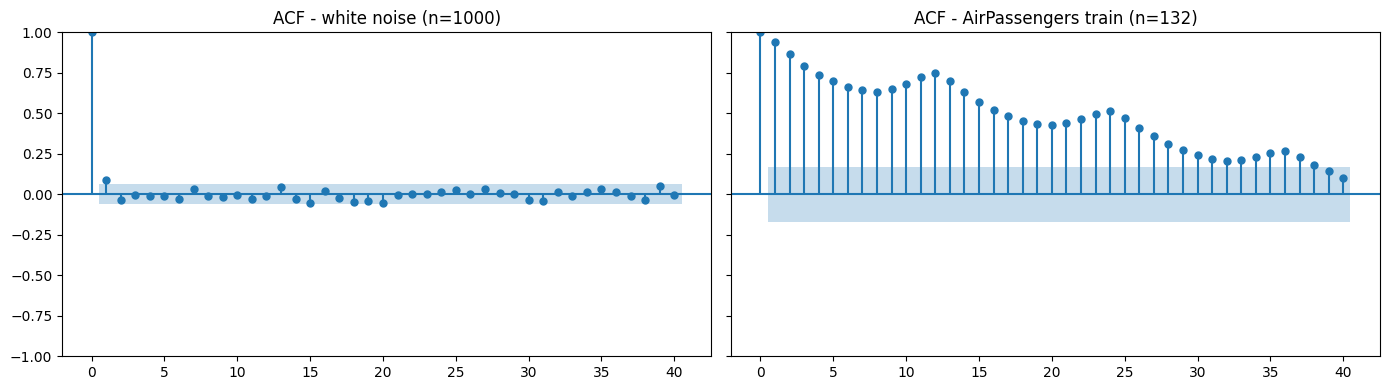

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_acf(wn, lags=40, bartlett_confint=False, ax=axes[0])
axes[0].set_title('ACF - white noise (n=1000)')
plot_acf(train, lags=40, bartlett_confint=False, ax=axes[1])
axes[1].set_title('ACF - AirPassengers train (n=132)')
plt.tight_layout()
plt.show()

**ACF của white noise (trái) và AirPassengers train (phải), cùng thang trục y, dải 95% là ±1.96/√n.** White noise gần như nằm hết trong dải (±0.062). AirPassengers giảm chậm từ 0.94 (lag 1), vượt dải (±0.171) ở 38/40 lag và gồ lên quanh lag 12 và 24. Dải của AirPassengers rộng hơn vì n nhỏ hơn (132 so với 1000), nhưng các thanh vẫn vượt xa.

**Năm điểm khác nhau giữa white noise và AirPassengers (train):**
1. **Hình dạng chuỗi:** white noise dao động quanh 0, không xu hướng, không mùa vụ; AirPassengers có xu hướng tăng và mùa vụ chu kỳ 12 tháng.
2. **ACF lag 1:** 0.087 (white noise) so với 0.942 (AirPassengers).
3. **Số lag vượt dải 95%:** 1/40 (mức ngẫu nhiên kỳ vọng khoảng 2/40) so với 38/40.
4. **Hình dạng ACF:** white noise rơi về sát 0 ngay sau lag 0; AirPassengers giảm rất chậm và gồ lên ở lag 12, 24.
5. **Khả năng dự báo:** white noise không có cấu trúc phụ thuộc nên không dự báo được từ quá khứ; AirPassengers có tự tương quan mạnh nên có thể mô hình hoá và dự báo.

# BT4. Dữ liệu thiếu (NaN): tạo, kiểm tra và xử lý

Tạo bản sao của train rồi cố ý xoá 12 tháng ngẫu nhiên (khoảng 9%, không xoá hai đầu chuỗi). `ap_true` giữ giá trị thật để đối chiếu khi vẽ. Kiểm tra bằng `isna().sum()`.

In [ ]:
# Tạo bộ sinh số ngẫu nhiên
rng_nan = np.random.default_rng(7)

ap_true = train.copy()
ap_nan = train.copy()

# Chọn ngẫu nhiên 12 vị trí dòng để tạo dữ liệu thiếu
miss_idx = rng_nan.choice(
    np.arange(1, len(ap_nan) - 1),
    size=12,
    replace=False
)

# Gán giá trị thiếu NaN vào các dòng đã chọn
ap_nan.iloc[miss_idx] = np.nan

# Đếm số lượng giá trị thiếu trong từng cột
print(
    "isna().sum():",
    ap_nan.isna().sum()
)

isna().sum(): 12


Xử lý missing bằng hai cách: forward-fill và nội suy tuyến tính theo thời gian.
* **Forward-fill (`ffill`):** Lấy giá trị hợp lệ gần nhất trong quá khứ đắp vào vị trí khuyết. Cách này đơn giản nhưng với chuỗi có độ dốc tăng mạnh, nó tạo ra các đoạn bậc thang nằm ngang không thực tế.
* **Interpolation (Nội suy):** Ước lượng điểm khuyết dựa trên hàm số nối giữa điểm quá khứ và tương lai (tuyến tính theo thời gian). Giữ được độ dốc và biên độ chu kỳ mượt mà.

In [ ]:
ap_ffill = ap_nan.ffill()
ap_interp = ap_nan.interpolate(method='time')

print("còn NaN sau ffill  :", ap_ffill.isna().sum())
print("còn NaN sau interp :", ap_interp.isna().sum())

còn NaN sau ffill  : 0
còn NaN sau interp : 0


Phát hiện outlier trên chuỗi sau nội suy bằng rolling mean/std và z-score.
* **Rolling Mean (Trung bình trượt 12 tháng):** Triệt tiêu hoàn toàn dao động mùa vụ trong năm để làm lộ rõ đường xu hướng tổng thể (*Underlying Trend*).
* **Rolling Std (Độ lệch chuẩn trượt 12 tháng):** Đo lường mức độ biến động/phương sai của dữ liệu trong chu kỳ 1 năm. Nếu đường này dốc lên $\rightarrow$ chuỗi vi phạm tính dừng về phương sai.

In [ ]:
x = ap_interp
roll_m = x.rolling(12).mean().shift(1)
roll_s = x.rolling(12).std().shift(1)

# abs(): tính độ lớn của chênh lệch, bỏ qua dấu âm/dương
# 3 * roll_s: ngưỡng chênh lệch bằng 3 lần độ lệch chuẩn quá khứ
# >: nếu chênh lệch lớn hơn ngưỡng thì đánh dấu True (outlier)
# Nếu không vượt ngưỡng thì đánh dấu False
out_roll = (x - roll_m).abs() > 3 * roll_s

# x - x.mean(): tính khoảng cách giữa mỗi giá trị và trung bình
# Chia cho độ lệch chuẩn để biểu diễn khoảng cách theo đơn vị std
# z cho biết mỗi giá trị cách trung bình bao nhiêu độ lệch chuẩn
z = (x - x.mean()) / x.std()

# z.abs(): lấy trị tuyệt đối của z-score
# > 3: đánh dấu True nếu giá trị cách trung bình hơn 3 độ lệch chuẩn
# Đây là ngưỡng phát hiện outlier theo quy tắc 3-sigma
out_z = z.abs() > 3
print("outlier theo rolling mean/std:", out_roll.sum())
print("outlier theo z-score         :", out_z.sum())

outlier theo rolling mean/std: 0
outlier theo z-score         : 0


Vẽ trước và sau khi xử lý: chuỗi có NaN (đường đứt ở chỗ thiếu), rồi chuỗi sau ffill và sau nội suy. Chấm đỏ là các giá trị được điền, đường xám nhạt là giá trị thật.

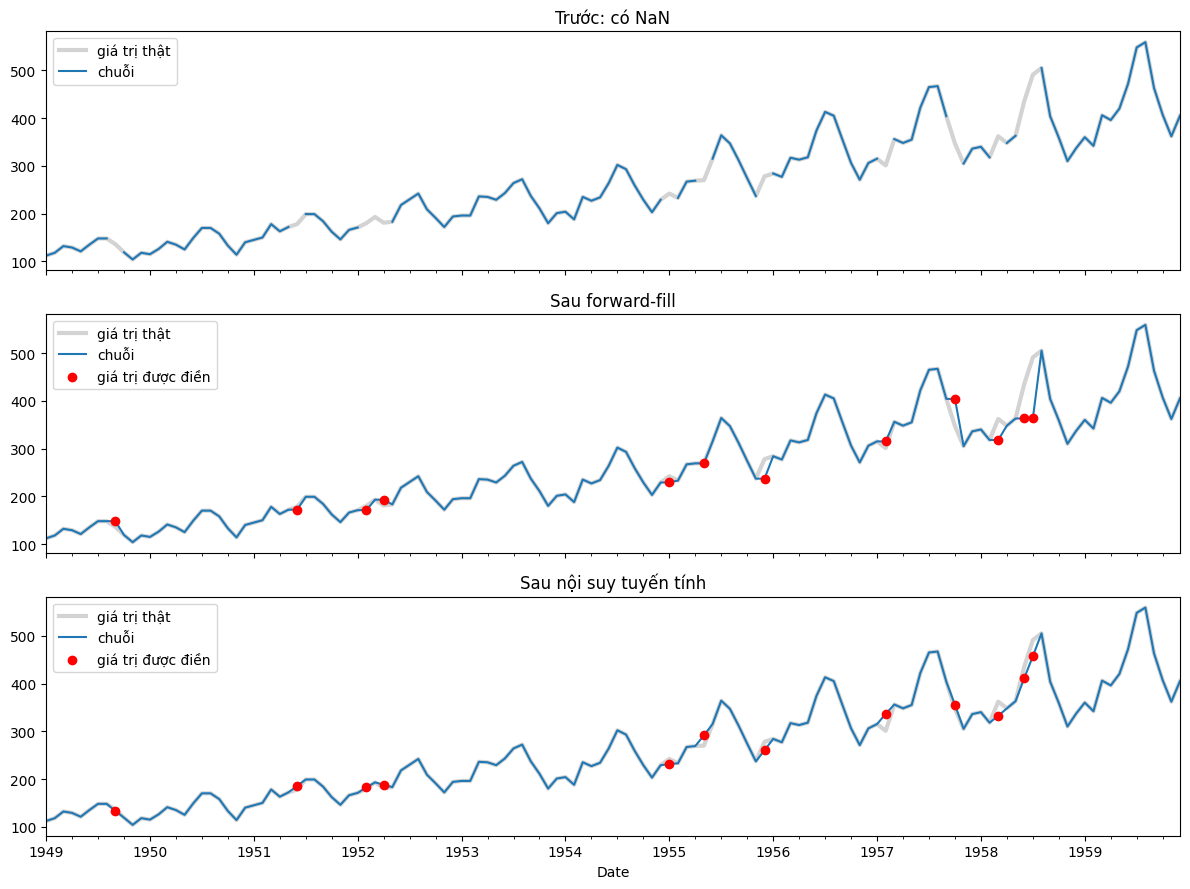

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
panels = [('Trước: có NaN', ap_nan), ('Sau forward-fill', ap_ffill), ('Sau nội suy tuyến tính', ap_interp)]
miss = ap_nan.isna()

for ax, (title, s) in zip(axes, panels):
    ap_true.plot(ax=ax, color='lightgray', linewidth=3, label='giá trị thật')
    s.plot(ax=ax, color='tab:blue', label='chuỗi')
    if title != 'Trước: có NaN':
        ax.scatter(s.index[miss], s[miss], color='red', zorder=3, label='giá trị được điền')
    ax.set_title(title)
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Ba sơ đồ cùng trục x và trục y.** Đường xám dày là giá trị thật, đường xanh là chuỗi đang xét, chấm đỏ là các giá trị được điền.

- **Trước:** 12/132 tháng bị xoá, hiện thành các đoạn đứt của đường xanh.
- **Forward-fill:** chấm đỏ nằm ngang bằng giá trị liền trước nên tạo "bậc thang", lệch xa ở những đoạn dốc. Ví dụ 1958-06 và 1958-07 đều điền 363 trong khi giá trị thật là 435 và 491.
- **Nội suy tuyến tính:** chấm đỏ nằm trên đoạn thẳng nối hai đầu nên bám sát chuỗi thật hơn (cùng hai tháng trên điền 411 và 457), nhưng vẫn không tái tạo được các đỉnh và đáy ngắn của mùa vụ.

**Outlier:** cả rolling mean/std và z-score đều không gắn cờ điểm nào trên chuỗi sau nội suy, nên không có outlier cần xử lý.

**Kết luận:** với chuỗi có xu hướng và mùa vụ, nội suy phù hợp hơn forward-fill.